# 네 가지 실패 모드

**이 노트북에서 할 일**

1. 휴관 목록에 필요 없는 기록이나 맞지 않는 기록을 더해 보내고, 답의 출처 표시와 지킬 말을 검사합니다.
2. 맞지 않는 두 기록의 순서만 바꿔 보내고 답을 비교합니다.
3. 틀린 상담 메모만 넣은 목록(Before)과 원문과 대조해 고친 목록(After)으로 같은 질문을 보냅니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 기록은 셀 안에 적고, 파일은 만들지 않습니다.

인터넷 서비스에 요청을 모두 5번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.8.0, tiktoken 0.14.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch08-context-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

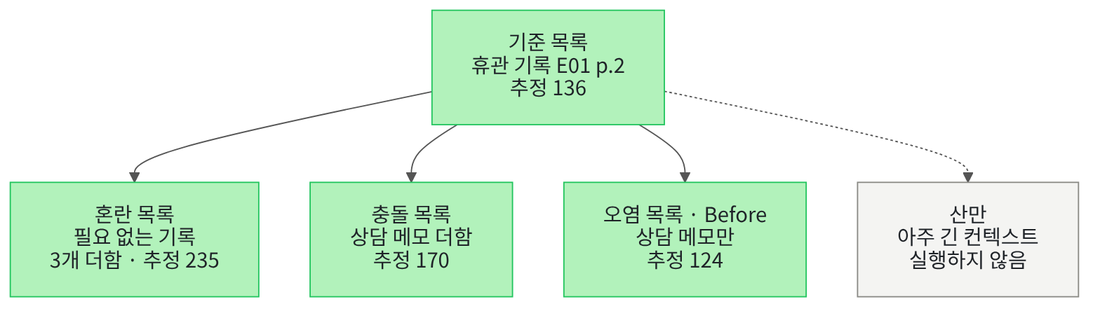

위에서 아래로 읽습니다. 맨 위 초록 상자는 03절 휴관 기록 하나만 넣은 기준 목록입니다.
아래 초록 상자 셋은 기준 목록에서 기록을 더하거나 바꾼 목록입니다. 상자마다 적힌 추정은 요청 전에 센 입력 토큰 수입니다.

회색 점선 상자인 산만은 이 노트북에서 실행하지 않습니다. 목록마다 답에서 무엇이 보였는지는 셀 출력으로 확인합니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~03절과 같은 패키지 판을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3" "tiktoken==0.14.0"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.8.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.8.0`, `tiktoken: 0.14.0` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

토큰 수를 세는 라이브러리와 모델 함수를 불러옵니다. 이 절도 파일을 쓰지 않아 모듈 `json`·`tempfile`은 부르지 않습니다.

In [2]:
# 토큰 수를 세는 라이브러리와 모델 함수를 불러옵니다
import tiktoken

from langchain.chat_models import init_chat_model

01~03절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


## 2. 03절에서 이어 쓰는 글과 수업 예산표

페르소나와 과업 명세는 02·03절과 글자까지 같습니다. 과업 명세는 문장마다 끝에 출처 표시를 적게 합니다.
출처 표시 `[E01 p.2]`는 모양을 보여 주는 예입니다.

In [4]:
# 02·03절과 같은 페르소나와 과업 명세를 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 과업 명세 줄에 `문장마다 끝에 출처를`이 있습니다.

수업 예산표도 01~03절과 같은 값으로 이어 씁니다. 수업 예산 600에서 출력 예약분 120과 여유분 40을 먼저 뗍니다.
먼저 01절과 같은 뺄셈 함수를 정의합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [5]:
# 수업 예산에서 출력 예약분과 여유분을 빼, 입력에 쓸 수 있는 토큰 수를 반환하는 함수를 정의합니다
def input_budget(total_budget, output_reserve, safety_margin):
    available = total_budget - output_reserve - safety_margin
    return available

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

세 값을 01~03절과 같게 담고 입력 가용분을 구합니다.
실행 전에 예상합니다. 01~03절처럼 440일 것입니다.

In [6]:
# 01~03절과 같은 수업 예산·출력 예약분·여유분으로 입력 가용분을 계산합니다
total_budget = 600
output_reserve = 120
safety_margin = 40
available = input_budget(total_budget, output_reserve, safety_margin)
print("수업 예산:", total_budget)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("입력 가용분:", available)

수업 예산: 600
출력 예약분: 120
여유분: 40
입력 가용분: 440


**결과 읽기** — 네 줄은 `수업 예산: 600`, `출력 예약분: 120`, `여유분: 40`, `입력 가용분: 440`입니다.
이 절에서 보내는 메시지 목록도 모두 입력 가용분 440 안에 들어야 합니다.

요청 전에 토큰 수를 셀 함수도 01~03절과 같은 코드로 정의합니다.
함수 `tiktoken.encoding_for_model()`은 모델 이름을 받아 토큰화 규칙 객체를 반환합니다.
함수 `count_tokens()`는 이 규칙 객체 `encoding`을 읽어 글 하나의 토큰 수를 반환합니다. 이 셀은 출력이 없습니다.

In [7]:
# 01~03절처럼 모델의 토큰화 규칙을 불러오고, 글 하나의 토큰 수를 반환하는 함수를 정의합니다
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")


def count_tokens(text):
    token_ids = encoding.encode(text)
    return len(token_ids)

**결과 읽기** — 규칙 객체를 만들고 함수를 정의만 하는 셀이라 출력이 없습니다.

모델 객체는 02·03절처럼 출력 예약분을 출력 상한(`max_tokens`)으로 주어 만듭니다. 이 셀은 요청을 보내지 않습니다.
마지막 줄 `assert`는 예산표의 출력 예약분이 모델 설정에 그대로 들어갔는지 확인합니다.

In [8]:
# 출력 예약분을 출력 상한으로 준 모델을 준비합니다(02·03절과 같은 설정)
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=output_reserve,
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)
print("출력 상한(max_tokens):", model.max_tokens)
assert model.max_tokens == output_reserve

모델 이름: gpt-5.4-mini
temperature: 0.0
출력 상한(max_tokens): 120


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`, `temperature: 0.0`, `출력 상한(max_tokens): 120`입니다. `assert`도 통과했습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

이 절은 03절의 휴관 업무를 이어 씁니다. 휴관 기록·질문·지킬 말은 03절과 글자까지 같습니다.
휴관 기록은 E01 2쪽 원문을 읽고 지킬 말을 남기며 줄인 기록입니다. 이 절에서는 이 기록을 맞는 기록의 기준으로 씁니다.

In [9]:
# 03절과 같은 휴관 기록·질문·지킬 말을 만듭니다
closure_note = {
    "출처": "E01 p.2",
    "기관": "미르시립도서관",
    "주제": "휴관",
    "내용": "매주 월요일은 정기 휴관일이고 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.",
}
closure_question = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
closure_keep_words = ["월요일", "법정 공휴일", "화요일"]
print("휴관 기록 출처:", closure_note["출처"])
print("질문:", closure_question)
print("지킬 말:", closure_keep_words)

휴관 기록 출처: E01 p.2
질문: 미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?
지킬 말: ['월요일', '법정 공휴일', '화요일']


**결과 읽기** — 출력 줄은 `휴관 기록 출처: E01 p.2`, `질문:` 줄, `지킬 말: ['월요일', '법정 공휴일', '화요일']`입니다.

03절 함수 `find_missing_words()`를 같은 코드로 정의합니다. 글 하나와 말 목록을 받아, 글에 없는 말만 목록으로 반환합니다.
이 절에서는 원문을 줄인 기록뿐 아니라 모델의 답 글에도 이 함수를 씁니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [10]:
# 글에 들어 있지 않은 지킬 말만 모아 반환하는 함수를 정의합니다(03절과 같은 코드)
def find_missing_words(text, words):
    missing = []
    for word in words:
        if word not in text:
            missing.append(word)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

02절 함수 `find_cited_notes()`도 같은 코드로 정의합니다. 답 글과 기록 목록을 받아, 출처 표시가 답 글에 들어 있는 기록만 반환합니다.
답에 적힌 출처 표시가 이번 목록에 넣은 기록에 없으면 빈 목록이 나옵니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [11]:
# 답 글에 출처 표시가 들어 있는 기록만 골라 반환하는 함수를 정의합니다(02절과 같은 코드)
def find_cited_notes(answer_text, notes):
    cited = []
    for note in notes:
        mark = "[" + note["출처"] + "]"
        if mark in answer_text:
            cited.append(note)
    return cited

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

03절 함수 `build_messages()`는 기록 하나만 받았습니다. 이 절은 한 목록에 기록을 여러 개 넣으므로, 기록 목록을 받는 함수를 새로 정의합니다.
user 글은 02절 근거 글처럼 기록마다 출처 표시를 붙인 한 줄, 빈 줄, 질문 순서입니다.
반복문 안에서는 글을 `+`로 이어 같은 이름에 다시 담기만 합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [12]:
# 기록 목록과 질문 하나로 Ch 7 모양의 메시지 목록을 만들어 반환하는 함수를 정의합니다
def build_notes_messages(notes, question):
    evidence_text = ""
    for note in notes:
        evidence_text = evidence_text + "[" + note["출처"] + "] " + note["내용"] + "\n"
    user_text = evidence_text + "\n" + "질문: " + question
    messages = [
        ("system", persona_text),
        ("developer", task_text),
        ("user", user_text),
    ]
    return messages

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

휴관 기록 하나만 넣은 목록을 만듭니다. 이 절에서는 이 목록을 기준 목록이라고 부르겠습니다.
기록이 하나면 user 글이 03절 `build_messages()`로 만든 휴관 목록과 같습니다.
실행 전에 예상합니다. 추정 입력은 03절 휴관 목록과 같은 136일 것입니다.

In [13]:
# 휴관 기록 하나만 넣은 기준 목록을 만들고 추정 입력을 셉니다(요청은 보내지 않습니다)
base_notes = [closure_note]
base_messages = build_notes_messages(base_notes, closure_question)
shared_tokens = count_tokens(persona_text) + count_tokens(task_text)
base_estimate = shared_tokens + count_tokens(base_messages[2][1])
print("기준 목록 user 글:")
print(base_messages[2][1])
print("기준 목록 추정 입력 합계:", base_estimate)

기준 목록 user 글:
[E01 p.2] 매주 월요일은 정기 휴관일이고 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.

질문: 미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?
기준 목록 추정 입력 합계: 136


**결과 읽기** — 라벨 줄 `기준 목록 user 글:` 아래 첫 줄은 `[E01 p.2] 매주 월요일은 정기 휴관일이고`로 시작합니다. 빈 줄 다음은 `질문:` 줄입니다.
마지막 줄은 `기준 목록 추정 입력 합계: 136`으로 03절 휴관 목록과 같습니다.
기준 목록은 7절 After에서 보냅니다. 3~6절은 이 목록에서 기록을 더하거나 바꿔 보냅니다.

## 3. 혼란 — 필요 없는 기록을 함께 넣기

컨텍스트에 넣은 자료 때문에 답이 틀어지는 경우를 Drew Breunig는 네 가지로 나눴습니다. LangChain 팀의 컨텍스트 엔지니어링 글이 이 이름을 옮겨 소개합니다.
이 절에서는 네 이름을 한국어로 오염·산만·혼란·충돌이라고 부르겠습니다. 이 이름들을 실패 모드라고 묶어 부릅니다.

- 오염(Context Poisoning): 틀린 내용이 컨텍스트에 들어가, 뒤에서 되풀이해 쓰이는 경우입니다.
- 산만(Context Distraction): 아주 긴 컨텍스트에 치우쳐, 모델이 학습한 것을 덜 쓰는 경우입니다.
- 혼란(Context Confusion): 질문에 필요 없는 내용이 컨텍스트에 있어, 모델이 그 내용을 답에 쓰는 경우입니다.
- 충돌(Context Clash): 컨텍스트 안의 정보끼리 서로 맞지 않는 경우입니다.

산만은 그 글에서 10만 토큰을 넘는 긴 기록의 사례로 나옵니다. 수업 예산 600으로는 만들 수 없어 이 노트북에서 실행하지 않습니다.
이름은 입력에서 무엇을 확인할지 정하는 데 씁니다. 목록에 그런 기록을 넣었다고 답이 틀어졌다고 적지 않고, 답을 읽어 확인합니다.

먼저 혼란입니다. 휴관 질문에 필요 없는 기록 세 개를 휴관 기록 뒤에 더합니다.
03절 대출 기록, 02절 주차 기록, 그리고 E02 2쪽 별빛제과 급여 기록입니다. 급여 기록은 다른 기관의 글인데 「공휴일」이라는 말이 들어 있습니다.

In [14]:
# 휴관 질문에 필요 없는 기록 세 개를 만들고, 휴관 기록과 함께 혼란 목록에 넣을 기록 목록을 만듭니다
loan_note = {"출처": "E01 p.3", "기관": "미르시립도서관", "주제": "대출", "내용": "회원 한 사람의 도서 대출 기준은 7권·14일이며, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다."}
parking_note = {"출처": "E01 p.5", "기관": "미르시립도서관", "주제": "주차", "내용": "회원은 최초 2시간 무료입니다."}
pay_note = {"출처": "E02 p.2", "기관": "별빛제과", "주제": "급여", "내용": "급여는 매월 25일에 지급되며, 25일이 주말이나 공휴일이면 그 전 영업일에 지급합니다."}
confusion_notes = [closure_note, loan_note, parking_note, pay_note]
confusion_sources = []
for note in confusion_notes:
    confusion_sources.append(note["출처"])
print("혼란 목록 기록 수:", len(confusion_notes))
print("혼란 목록 기록 출처:", confusion_sources)

혼란 목록 기록 수: 4
혼란 목록 기록 출처: ['E01 p.2', 'E01 p.3', 'E01 p.5', 'E02 p.2']


**결과 읽기** — 출력 줄은 `혼란 목록 기록 수: 4`와 `혼란 목록 기록 출처: ['E01 p.2', 'E01 p.3', 'E01 p.5', 'E02 p.2']`입니다.
휴관 질문에 필요한 기록은 첫 기록 하나이고, 나머지 셋은 필요 없는 기록입니다.

답을 받은 뒤 두 가지를 검사하는 함수를 정의합니다. 답의 출처 표시와 같은 기록의 출처, 그리고 답에서 빠진 휴관 지킬 말입니다.
앞의 두 함수를 그대로 부르고, 결과는 한국어 키 두 개의 딕셔너리로 반환합니다. 지킬 말 목록은 바깥 이름 `closure_keep_words`를 읽습니다.

이 검사는 Ch 7 01절 확인 단어 표시처럼 말이 있는지만 봅니다. 답의 품질 점수가 아닙니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [15]:
# 답 글과 넣은 기록 목록으로, 답의 출처 표시와 같은 기록과 답에서 빠진 지킬 말을 모아 반환하는 함수를 정의합니다
def check_answer(answer_text, notes):
    cited = find_cited_notes(answer_text, notes)
    cited_sources = []
    for note in cited:
        cited_sources.append(note["출처"])
    missing = find_missing_words(answer_text, closure_keep_words)
    check = {"답의 출처 표시와 같은 기록": cited_sources, "답에서 빠진 지킬 말": missing}
    return check

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

혼란 목록을 만들고 추정 입력을 셉니다. 질문·페르소나·과업 명세는 기준 목록과 같고, user 글의 기록만 늘었습니다.
실행 전에 예상합니다. 기록 세 개가 늘어 기준 목록 136보다 커지지만, 입력 가용분 440 안에는 들 것입니다.

In [16]:
# 기록 네 개를 넣은 혼란 목록을 만들고 추정 입력을 입력 가용분과 비교합니다(요청은 보내지 않습니다)
confusion_messages = build_notes_messages(confusion_notes, closure_question)
confusion_estimate = shared_tokens + count_tokens(confusion_messages[2][1])
print("혼란 목록 추정 입력 합계:", confusion_estimate)
print("기준 목록보다 늘어난 토큰 수:", confusion_estimate - base_estimate)
print("입력 가용분 안에 드는가:", confusion_estimate <= available)

혼란 목록 추정 입력 합계: 235
기준 목록보다 늘어난 토큰 수: 99
입력 가용분 안에 드는가: True


**결과 읽기** — 출력 줄은 `혼란 목록 추정 입력 합계: 235`, `기준 목록보다 늘어난 토큰 수: 99`, `입력 가용분 안에 드는가: True`입니다.
필요 없는 기록 세 개가 99토큰을 더했습니다.

혼란 목록을 보냅니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.
실행 전에 예상해 봅니다. 모델이 필요 없는 기록을 답에 쓰면, 대출·주차·급여 이야기나 그 출처 표시가 답에 나올 것입니다.

In [17]:
# 혼란 목록을 보냅니다(요청 1번)
confusion_response = model.invoke(confusion_messages)
print("답:")
print(confusion_response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다. [E01 p.2] 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다.`입니다.
둘째 문장은 `공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.`이고, 두 문장 끝에 모두 `[E01 p.2]`가 붙었습니다.
대출·주차·급여 이야기는 답에 나오지 않았습니다. 실행마다 답 문장이 달라질 수 있습니다.

In [18]:
# 혼란 목록 답의 토큰 수와 끝난 이유를 보고, 출처 표시와 지킬 말을 검사합니다
confusion_usage = confusion_response.usage_metadata
print("실제 입력 토큰 수:", confusion_usage["input_tokens"])
print("실제 출력 토큰 수:", confusion_usage["output_tokens"])
print("끝난 이유:", confusion_response.response_metadata["finish_reason"])
confusion_check = check_answer(confusion_response.text, confusion_notes)
print("혼란 목록 답 검사:", confusion_check)

실제 입력 토큰 수: 249
실제 출력 토큰 수: 66
끝난 이유: stop
혼란 목록 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 249`, `실제 출력 토큰 수: 66`, `끝난 이유: stop`입니다.
마지막 줄은 `혼란 목록 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}`입니다.
네 기록 가운데 휴관 기록 하나만 출처로 찾았고, 빠진 지킬 말도 없습니다.

필요 없는 기록 세 개를 넣었지만, 이번 답에서는 모델이 그 기록을 쓴 흔적을 찾지 못했습니다.
그래서 「혼란이 생겼다」가 아니라 「혼란 조건을 넣었고, 이번 답에서는 보이지 않았다」고 적습니다.
대신 추정 입력은 기준 목록보다 99토큰 많았습니다. 이 결과는 질문 하나를 한 번 보낸 결과입니다.

## 4. 충돌 — 맞지 않는 기록을 함께 넣기

이번에는 휴관 기록과 맞지 않는 기록을 더합니다. 앞선 상담에서 누군가 원문을 확인하지 않고 적어 둔 상담 메모라고 가정합니다.

메모 글은 이 노트북이 일부러 틀리게 적었습니다. 원문은 법정 공휴일에도 휴관한다고 했지만, 메모는 공휴일에 문을 연다고 적었습니다.
키는 02절 기록과 같습니다. 다만 출처가 문서 쪽이 아니라 `상담 메모`입니다.

실행 전에 예상합니다. 두 기록이 한 목록에 있으니, 추정 입력은 기준 목록보다 크고 혼란 목록보다 작을 것입니다.

In [19]:
# 원문과 다른 상담 메모를 만들고, 휴관 기록 뒤에 더한 충돌 목록의 추정 입력을 셉니다(요청은 보내지 않습니다)
memo_note = {
    "출처": "상담 메모",
    "기관": "미르시립도서관",
    "주제": "휴관",
    "내용": "미르시립도서관은 매주 월요일 하루만 휴관하고, 공휴일에는 문을 엽니다.",
}
clash_notes = [closure_note, memo_note]
clash_messages = build_notes_messages(clash_notes, closure_question)
clash_estimate = shared_tokens + count_tokens(clash_messages[2][1])
print("충돌 목록 user 글:")
print(clash_messages[2][1])
print("충돌 목록 추정 입력 합계:", clash_estimate)

충돌 목록 user 글:
[E01 p.2] 매주 월요일은 정기 휴관일이고 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.
[상담 메모] 미르시립도서관은 매주 월요일 하루만 휴관하고, 공휴일에는 문을 엽니다.

질문: 미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?
충돌 목록 추정 입력 합계: 170


**결과 읽기** — 라벨 줄 `충돌 목록 user 글:` 아래 두 줄이 기록입니다. 첫 줄은 `[E01 p.2]`, 둘째 줄은 `[상담 메모]`로 시작합니다.
마지막 줄은 `충돌 목록 추정 입력 합계: 170`입니다.
첫 줄은 공휴일에도 휴관한다고 하고, 둘째 줄은 공휴일에 문을 연다고 합니다. 같은 기관·같은 주제인데 두 기록이 맞지 않습니다.

충돌 목록을 보냅니다. 실행 전에 예상해 봅니다. 답이 두 기록 가운데 하나를 따르거나, 두 기록이 다르다고 밝힐 수 있습니다.

In [20]:
# 충돌 목록을 보냅니다(요청 1번)
clash_response = model.invoke(clash_messages)
print("답:")
print(clash_response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다. [E01 p.2] 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 3절 혼란 목록의 답과 글자까지 같은 두 문장입니다. 두 문장 끝에 모두 `[E01 p.2]`가 붙었습니다.
답은 휴관 기록을 따랐고, 상담 메모의 「공휴일에는 문을 엽니다」는 쓰지 않았습니다.
두 기록이 서로 다르다는 말은 답에 없습니다. 답만 읽으면 목록에 맞지 않는 기록이 있었는지 알 수 없습니다.

In [21]:
# 충돌 목록 답의 토큰 수와 끝난 이유를 보고, 출처 표시와 지킬 말을 검사합니다
clash_usage = clash_response.usage_metadata
print("실제 입력 토큰 수:", clash_usage["input_tokens"])
print("실제 출력 토큰 수:", clash_usage["output_tokens"])
print("끝난 이유:", clash_response.response_metadata["finish_reason"])
clash_check = check_answer(clash_response.text, clash_notes)
print("충돌 목록 답 검사:", clash_check)

실제 입력 토큰 수: 184
실제 출력 토큰 수: 66
끝난 이유: stop
충돌 목록 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 184`, `실제 출력 토큰 수: 66`, `끝난 이유: stop`입니다.
마지막 줄은 `충돌 목록 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}`입니다. 상담 메모는 출처로 찾지 못했습니다.

충돌 조건을 넣었지만, 이번 답은 원문과 맞는 휴관 기록 쪽을 따랐습니다. 그렇다고 맞지 않는 기록을 넣어도 괜찮다는 뜻은 아닙니다.
모델이 왜 휴관 기록을 따랐는지는 이번 실행으로 알 수 없습니다. 기록 순서를 바꾸면 어떻게 되는지 다음 절에서 봅니다.

## 5. 값 바꿔 보기 — 두 기록의 순서만 바꾸기

바꾸는 것은 충돌 목록 안 두 기록의 순서 하나뿐입니다. 상담 메모를 앞에, 휴관 기록을 뒤에 둡니다.
충돌은 나중에 들어온 정보가 앞의 정보와 맞지 않을 때 생긴다고 설명됩니다. 그래서 어느 기록이 나중에 오는지만 바꿔 봅니다.

실행 전에 예상합니다. 글자는 같고 순서만 달라, 추정 입력은 충돌 목록과 같은 170일 것입니다.

In [22]:
# 상담 메모를 앞에 둔 목록을 만들고 추정 입력을 셉니다(요청은 보내지 않습니다)
reversed_notes = [memo_note, closure_note]
reversed_messages = build_notes_messages(reversed_notes, closure_question)
reversed_estimate = shared_tokens + count_tokens(reversed_messages[2][1])
print("순서를 바꾼 목록의 첫 기록 출처:", reversed_notes[0]["출처"])
print("순서를 바꾼 목록 추정 입력 합계:", reversed_estimate)
print("충돌 목록과 추정 입력이 같은가:", reversed_estimate == clash_estimate)

순서를 바꾼 목록의 첫 기록 출처: 상담 메모
순서를 바꾼 목록 추정 입력 합계: 170
충돌 목록과 추정 입력이 같은가: True


**결과 읽기** — 출력 줄은 `순서를 바꾼 목록의 첫 기록 출처: 상담 메모`, `순서를 바꾼 목록 추정 입력 합계: 170`입니다.
마지막 줄은 `충돌 목록과 추정 입력이 같은가: True`입니다.

순서를 바꾼 목록을 보냅니다. 실행 전에 예상해 봅니다. 4절 답은 앞에 둔 휴관 기록을 따랐습니다. 앞에 둔 기록을 따른다면 이번 답은 상담 메모를 따를 것입니다.

In [23]:
# 순서를 바꾼 목록을 보내고, 출처 표시와 지킬 말을 검사합니다(요청 1번)
reversed_response = model.invoke(reversed_messages)
print("답:")
print(reversed_response.text)
reversed_check = check_answer(reversed_response.text, reversed_notes)
print("순서를 바꾼 목록 답 검사:", reversed_check)

답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다. [E01 p.2] 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]
순서를 바꾼 목록 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}


**결과 읽기** — 라벨 줄 `답:` 아래 답은 4절 충돌 목록의 답과 같은 두 문장이고, 끝마다 `[E01 p.2]`가 붙었습니다.
마지막 줄은 `순서를 바꾼 목록 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}`입니다.
상담 메모가 앞에 와도 이번 답은 휴관 기록을 따랐습니다.

순서를 바꿔도 이번에는 답이 달라지지 않았습니다. 두 순서를 한 번씩 보낸 결과라, 순서가 답에 영향을 주지 않는다고 결론 내리지는 않습니다.

## 6. Before — 상담 메모만 든 목록으로 답하기

이번에는 휴관 기록 자리에 상담 메모만 들어간 목록입니다. 02절처럼 기록을 적어 두고 요청마다 골라 넣으면, 틀린 기록도 요청마다 다시 들어갑니다.
오염은 이렇게 틀린 내용이 컨텍스트에 들어가 되풀이해 쓰이는 경우입니다.

실행 전에 예상합니다. 기록이 하나라 추정 입력은 기준 목록 136보다 작을 것입니다.

In [24]:
# 상담 메모 하나만 넣은 목록을 만들고 추정 입력을 셉니다(요청은 보내지 않습니다)
before_notes = [memo_note]
before_messages = build_notes_messages(before_notes, closure_question)
before_estimate = shared_tokens + count_tokens(before_messages[2][1])
print("Before 목록 기록 출처:", before_notes[0]["출처"])
print("Before 목록 추정 입력 합계:", before_estimate)

Before 목록 기록 출처: 상담 메모
Before 목록 추정 입력 합계: 124


**결과 읽기** — 출력 줄은 `Before 목록 기록 출처: 상담 메모`와 `Before 목록 추정 입력 합계: 124`입니다.
기록을 넣기 전에 원문과 대조하지 않고 그대로 보냅니다.

상담 메모만 든 목록을 보냅니다. 질문·페르소나·과업 명세·모델 설정은 After와 같습니다.
실행 전에 예상해 봅니다. 목록에 원문과 다른 메모만 있으니, 답도 메모를 따라 공휴일에 문을 연다고 할 것입니다.

In [25]:
# 상담 메모만 든 목록을 보냅니다(요청 1번)
before_response = model.invoke(before_messages)
print("답:")
print(before_response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다 [E01 p.2]. 공휴일에는 문을 열며, 공휴일이 월요일과 겹쳐도 휴관하지 않습니다 [E01 p.2].


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다 [E01 p.2].`입니다.
둘째 문장은 `공휴일에는 문을 열며, 공휴일이 월요일과 겹쳐도 휴관하지 않습니다 [E01 p.2].`입니다.
원문은 법정 공휴일에도 휴관하고, 월요일과 겹치면 화요일도 휴관한다고 했습니다. 답은 상담 메모의 틀린 내용을 그대로 되풀이했습니다.

오류는 나지 않았습니다. 두 문장 끝의 출처 표시는 E01 2쪽을 가리키지만, 이 목록에는 E01 2쪽 기록이 없었습니다.
실행마다 답 문장과 출처 표시가 달라질 수 있습니다.

In [26]:
# Before 답의 토큰 수와 끝난 이유를 보고, 출처 표시와 지킬 말을 검사합니다
before_usage = before_response.usage_metadata
print("실제 입력 토큰 수:", before_usage["input_tokens"])
print("실제 출력 토큰 수:", before_usage["output_tokens"])
print("끝난 이유:", before_response.response_metadata["finish_reason"])
before_check = check_answer(before_response.text, before_notes)
print("Before 답 검사:", before_check)

실제 입력 토큰 수: 138
실제 출력 토큰 수: 60
끝난 이유: stop
Before 답 검사: {'답의 출처 표시와 같은 기록': [], '답에서 빠진 지킬 말': ['법정 공휴일', '화요일']}


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 138`, `실제 출력 토큰 수: 60`, `끝난 이유: stop`입니다.
마지막 줄은 `Before 답 검사: {'답의 출처 표시와 같은 기록': [], '답에서 빠진 지킬 말': ['법정 공휴일', '화요일']}`입니다.
답의 출처 표시와 같은 기록은 빈 목록이고, 휴관 지킬 말 두 개가 답에서 빠졌습니다.

답의 출처 표시 「[E01 p.2]」는 이 목록의 어느 기록과도 같지 않아 빈 목록이 나왔습니다. 과업 명세에 예로 적은 표시와 같은 모양입니다.
모델이 왜 이 표시를 적었는지는 이번 실행으로 알 수 없습니다.
틀린 기록 하나가 목록에 들어가자, 틀린 내용이 문서 출처를 단 답으로 나왔습니다. 이 결과는 질문 하나를 한 번 보낸 결과입니다.

## 7. After — 원문과 대조해 고친 기록으로 답하기

고치는 곳은 목록에 넣는 기록 하나입니다. 넣기 전에 상담 메모를 03절 지킬 말로 검사하고, 출처가 문서 쪽인지 봅니다.
지킬 말은 03절에서 E01 2쪽 원문을 읽고 고른 말입니다. 빠진 말이 있으면 메모를 빼고, 원문을 대조해 줄인 휴관 기록을 넣습니다.

바꾼 목록은 2절 기준 목록과 같아야 합니다. 마지막 줄 `assert`로 확인합니다.

실행 전에 예상합니다. 상담 메모에서는 공휴일과 화요일 쪽 지킬 말이 빠졌을 것입니다.

In [27]:
# 상담 메모를 지킬 말로 검사한 뒤, 원문과 대조한 휴관 기록으로 바꾼 목록을 만듭니다(요청은 보내지 않습니다)
memo_missing = find_missing_words(memo_note["내용"], closure_keep_words)
print("상담 메모 출처:", memo_note["출처"])
print("상담 메모에서 빠진 지킬 말:", memo_missing)
after_notes = [closure_note]
after_messages = build_notes_messages(after_notes, closure_question)
print("After 목록 기록 출처:", after_notes[0]["출처"])
assert after_messages == base_messages

상담 메모 출처: 상담 메모
상담 메모에서 빠진 지킬 말: ['법정 공휴일', '화요일']
After 목록 기록 출처: E01 p.2


**결과 읽기** — 출력 줄은 `상담 메모 출처: 상담 메모`와 `상담 메모에서 빠진 지킬 말: ['법정 공휴일', '화요일']`입니다.
마지막 줄은 `After 목록 기록 출처: E01 p.2`이고, `assert`도 통과했습니다. After 목록은 2절 기준 목록과 같습니다.
메모에는 원문으로 되짚어 갈 쪽 번호가 없고, 지킬 말도 두 개 빠졌습니다.

고친 목록을 보냅니다. 실행 전에 예상합니다. 답에 법정 공휴일과 화요일 조건이 들어갈 것입니다.

In [28]:
# 원문과 대조한 휴관 기록이 든 목록을 보냅니다(요청 1번)
after_response = model.invoke(after_messages)
print("답:")
print(after_response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다. [E01 p.2] 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 두 문장이고, 끝마다 `[E01 p.2]`가 붙었습니다. 첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다.`입니다.
둘째 문장은 `공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.`입니다. 원문의 두 조건이 답에 들어갔습니다.

이 답은 3~5절 세 답과 글자까지 같습니다. 휴관 기록이 든 네 목록은 이번에 기록을 더하거나 순서를 바꿔도 답이 같았습니다.

In [29]:
# After 답의 토큰 수·끝난 이유·추정과의 차이를 보고, 출처 표시와 지킬 말을 검사합니다
after_usage = after_response.usage_metadata
print("실제 입력 토큰 수:", after_usage["input_tokens"])
print("실제 출력 토큰 수:", after_usage["output_tokens"])
print("끝난 이유:", after_response.response_metadata["finish_reason"])
input_gap = after_usage["input_tokens"] - base_estimate
print("실제 입력 - 추정 입력:", input_gap)
print("차이가 여유분 안에 드는가:", input_gap <= safety_margin)
after_check = check_answer(after_response.text, after_notes)
print("After 답 검사:", after_check)

실제 입력 토큰 수: 150
실제 출력 토큰 수: 66
끝난 이유: stop
실제 입력 - 추정 입력: 14
차이가 여유분 안에 드는가: True
After 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 150`, `실제 출력 토큰 수: 66`, `끝난 이유: stop`입니다.
그 아래 `실제 입력 - 추정 입력: 14`와 `차이가 여유분 안에 드는가: True`가 나왔습니다. 차이 14는 01~03절과 같은 값입니다.
마지막 줄은 `After 답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': []}`입니다.

Before 목록과 After 목록의 차이는 넣은 기록 하나였습니다. After 답에서는 출처 표시가 넣은 기록과 이어졌고, 빠진 지킬 말도 없었습니다.
Before 답에는 「공휴일」이라는 말이 있었지만 뜻은 원문과 반대였습니다. 이번에는 「법정 공휴일」과 「화요일」이 없어 검사가 빠진 말을 찾았습니다.

「화요일에는 휴관하지 않습니다」처럼 말은 있고 뜻이 반대인 답은 이 검사로 찾지 못합니다. 그런 답은 원문과 나란히 놓고 사람이 읽습니다.

## 정리

- 혼란 목록과 충돌 목록을 보냈지만, 이번 답에서는 두 경우 모두 틀어진 곳을 찾지 못했습니다. 넣은 조건과 답에서 확인한 것은 따로 적습니다.
- 상담 메모와 휴관 기록의 순서를 바꿔도 이번 답은 휴관 기록을 따랐고, 두 기록이 맞지 않는다는 말은 답에 없었습니다.
- 상담 메모만 넣은 Before 답은 공휴일에 문을 연다는 틀린 내용을 되풀이했습니다. 원문과 대조한 기록으로 바꾼 After 답에는 두 조건이 들어갔습니다.

다음 05절에서는 같은 근거를 둔 채 입력 길이만 늘려, 답이 달라지는지 잽니다.